# Mantenimiento vehicular en las compras públicas de Ecuador

El análisis sigue los procesos de **Subasta Inversa Electrónica** con apertura en 2025 y un código CPC del grupo **87141**. El proceso, la adjudicación y el contrato tienen unidades distintas. Las firmas posteriores a 2025 se incluyen cuando corresponden a procesos abiertos en ese año.

El cuaderno usa la configuración de PostgreSQL de la Fase 2 en este equipo, o las variables de libpq si se define PGDATABASE. La revisión de oferentes y plazos usa los ZIP identificados por sus hashes en PostgreSQL.

[Fuente de SERCOP](https://datosabiertos.compraspublicas.gob.ec/PLATAFORMA/datos-abiertos/) · [Referencia OCDS](https://standard.open-contracting.org/latest/en/schema/reference/) · [Nota de hallazgos](../docs/fase-3-hallazgos.md)

In [1]:
from collections import Counter, defaultdict
from decimal import Decimal
from html import escape
from io import BytesIO
import os
from pathlib import Path
from statistics import quantiles
import sys

from IPython.display import Image, Markdown, display
from matplotlib import pyplot as plt
from matplotlib.ticker import FuncFormatter
import psycopg
from psycopg.rows import dict_row

raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (raiz / "scripts" / "capturar_sercop.py").is_file():
    raise FileNotFoundError("Ejecuta el cuaderno desde la raíz del proyecto o su carpeta notebooks.")
sys.path.insert(0, str(raiz))

from scripts.auditar_sercop import filas_del_corte, leer_zip
from scripts.capturar_sercop import leer_crudo

config = {}
if not os.getenv("PGDATABASE"):
    runtime = Path(os.environ["LOCALAPPDATA"]) / "compras-publicas-ecuador"
    config = dict(
        host="127.0.0.1", port=55432, dbname="compras_publicas",
        user="compras_pipeline", passfile=str(runtime / "pgpass.conf"),
    )

vigencia = "p.mes >= DATE '2025-01-01' AND p.mes < DATE '2026-01-01'"
with psycopg.connect(**config, row_factory=dict_row, connect_timeout=5) as conexion:
    conexion.execute("SET TRANSACTION ISOLATION LEVEL REPEATABLE READ READ ONLY")
    cortes = conexion.execute('''
        SELECT p.*, c.sha256_zip, c.cargado_en
        FROM analitico.calidad_mensual p
        JOIN limpio.corte c USING (mes)
        WHERE ''' + vigencia + ' ORDER BY p.mes').fetchall()
    procesos = conexion.execute('''
        SELECT p.ocid, p.mes, p.apertura, p.entidad_id, p.entidad_nombre,
               h.numero_oferentes,
               EXISTS (SELECT 1 FROM analitico.hecho_adjudicacion a WHERE a.ocid = p.ocid) AS adjudicado
        FROM analitico.piloto_87141 p
        JOIN analitico.hecho_proceso h USING (ocid)
        WHERE ''' + vigencia + ' ORDER BY p.ocid').fetchall()
    contratos = conexion.execute('''
        SELECT c.ocid, c.contrato_id, c.firma, c.moneda, c.monto,
               p.apertura, p.entidad_nombre, p.objeto,
               ARRAY(SELECT r.cpc FROM analitico.proceso_rubro r
                     WHERE r.ocid = p.ocid ORDER BY r.cpc) AS cpcs,
               EXISTS (SELECT 1 FROM analitico.contrato_proveedor cp
                       WHERE cp.ocid = c.ocid AND cp.contrato_id = c.contrato_id) AS tiene_proveedor
        FROM analitico.hecho_contrato c
        JOIN analitico.piloto_87141 p USING (ocid)
        WHERE ''' + vigencia + ' ORDER BY c.ocid, c.contrato_id').fetchall()

assert [c["mes"].month for c in cortes] == list(range(1, 13))
assert all(c["total_portal"] == c["procesos"] for c in cortes)
assert len(procesos) == len({p["ocid"] for p in procesos}) == sum(c["procesos_piloto"] for c in cortes)

def numero(valor, decimales=0):
    return f"{valor:,.{decimales}f}".translate(str.maketrans(",.", ".,"))

def porcentaje(parte, total):
    return f"{numero(100 * parte / total, 1)} %" if total else "Sin base"

def tabla(columnas, filas):
    def linea(valores):
        celdas = [escape(str(v)).replace("|", "&#124;") for v in valores]
        return "| " + " | ".join(celdas) + " |"

    display(Markdown("\n".join([linea(columnas), linea(["---"] * len(columnas)), *map(linea, filas)])))

total_modalidad = sum(c["procesos"] for c in cortes)
total_sin_cpc = sum(c["sin_cpc"] for c in cortes)
tabla(
    ("Control", "Resultado"),
    [
        ("Carga en PostgreSQL", max(c["cargado_en"] for c in cortes).isoformat(timespec="seconds")),
        ("Procesos de la modalidad", numero(total_modalidad)),
        ("Procesos sin CPC", f"{numero(total_sin_cpc)} ({porcentaje(total_sin_cpc, total_modalidad)})"),
        ("Procesos del piloto", numero(len(procesos))),
        ("Entidades del piloto", numero(len({p["entidad_id"] for p in procesos}))),
    ],
)

| Control | Resultado |
| --- | --- |
| Carga en PostgreSQL | 2026-11-22T16:34:19-05:00 |
| Procesos de la modalidad | 18.333 |
| Procesos sin CPC | 1.014 (5,5 %) |
| Procesos del piloto | 239 |
| Entidades del piloto | 181 |

## Frecuencia de compradores

Una entidad es recurrente si aparece en al menos dos meses distintos. El ranking prioriza meses activos, luego procesos y finalmente el nombre.

In [2]:
por_entidad = defaultdict(list)
for proceso in procesos:
    por_entidad[proceso["entidad_id"]].append(proceso)

ranking = [
    (grupo[0]["entidad_nombre"], len(grupo), sorted({p["mes"].month for p in grupo}))
    for grupo in por_entidad.values()
]
ranking.sort(key=lambda r: (-len(r[2]), -r[1], r[0].casefold()))

nombres_mes = "Ene Feb Mar Abr May Jun Jul Ago Sep Oct Nov Dic".split()
tabla(
    ("Entidad", "Procesos", "Meses activos", "Meses observados"),
    [(nombre, cantidad, len(meses), ", ".join(nombres_mes[m - 1] for m in meses))
     for nombre, cantidad, meses in ranking[:6]],
)
segmentos = [
    ("Un proceso", [r for r in ranking if r[1] == 1]),
    ("Varios procesos en un mes", [r for r in ranking if r[1] > 1 and len(r[2]) == 1]),
    ("Aperturas en dos o más meses", [r for r in ranking if len(r[2]) >= 2]),
]
tabla(
    ("Frecuencia", "Entidades", "Procesos", "Proporción de procesos"),
    [(segmento, len(grupo), sum(r[1] for r in grupo),
      porcentaje(sum(r[1] for r in grupo), len(procesos))) for segmento, grupo in segmentos],
)

| Entidad | Procesos | Meses activos | Meses observados |
| --- | --- | --- | --- |
| GOBIERNO AUTONOMO DESCENTRALIZADO DEL DISTRITO METROPOLITANO DE QUITO | 5 | 5 | Abr, Jun, Jul, Sep, Nov |
| GOBIERNO AUTONOMO DESCENTRALIZADO MUNICIPAL DE ZAMORA | 4 | 4 | Mar, Abr, Sep, Nov |
| GOBIERNO AUTONOMO DESCENTRALIZADO DE LA PROVINCIA DE SUCUMBIOS | 5 | 3 | Jul, Oct, Nov |
| MUNICIPIO DE MILAGRO | 5 | 3 | Jun, Ago, Sep |
| EMPRESA PUBLICA MUNICIPAL MANCOMUNADA DE ASEO INTEGRAL DE LOS CANTONES DE CAÑAR BIBLIAN SUSCAL Y EL TAMBO | 4 | 3 | Mar, Abr, May |
| GOBIERNO AUTONOMO DESCENTRALIZADO DE LA PROVINCIA DE ORELLANA | 4 | 3 | Abr, Jul, Dic |

| Frecuencia | Entidades | Procesos | Proporción de procesos |
| --- | --- | --- | --- |
| Un proceso | 145 | 145 | 60,7 % |
| Varios procesos en un mes | 4 | 8 | 3,3 % |
| Aperturas en dos o más meses | 32 | 86 | 36,0 % |

## Calendario de aperturas

El panel superior cuenta procesos del rubro. El inferior divide ese conteo por las subastas inversas del mes con algún CPC informado. Este porcentaje usa la base clasificable del mes. La serie describe 2025.

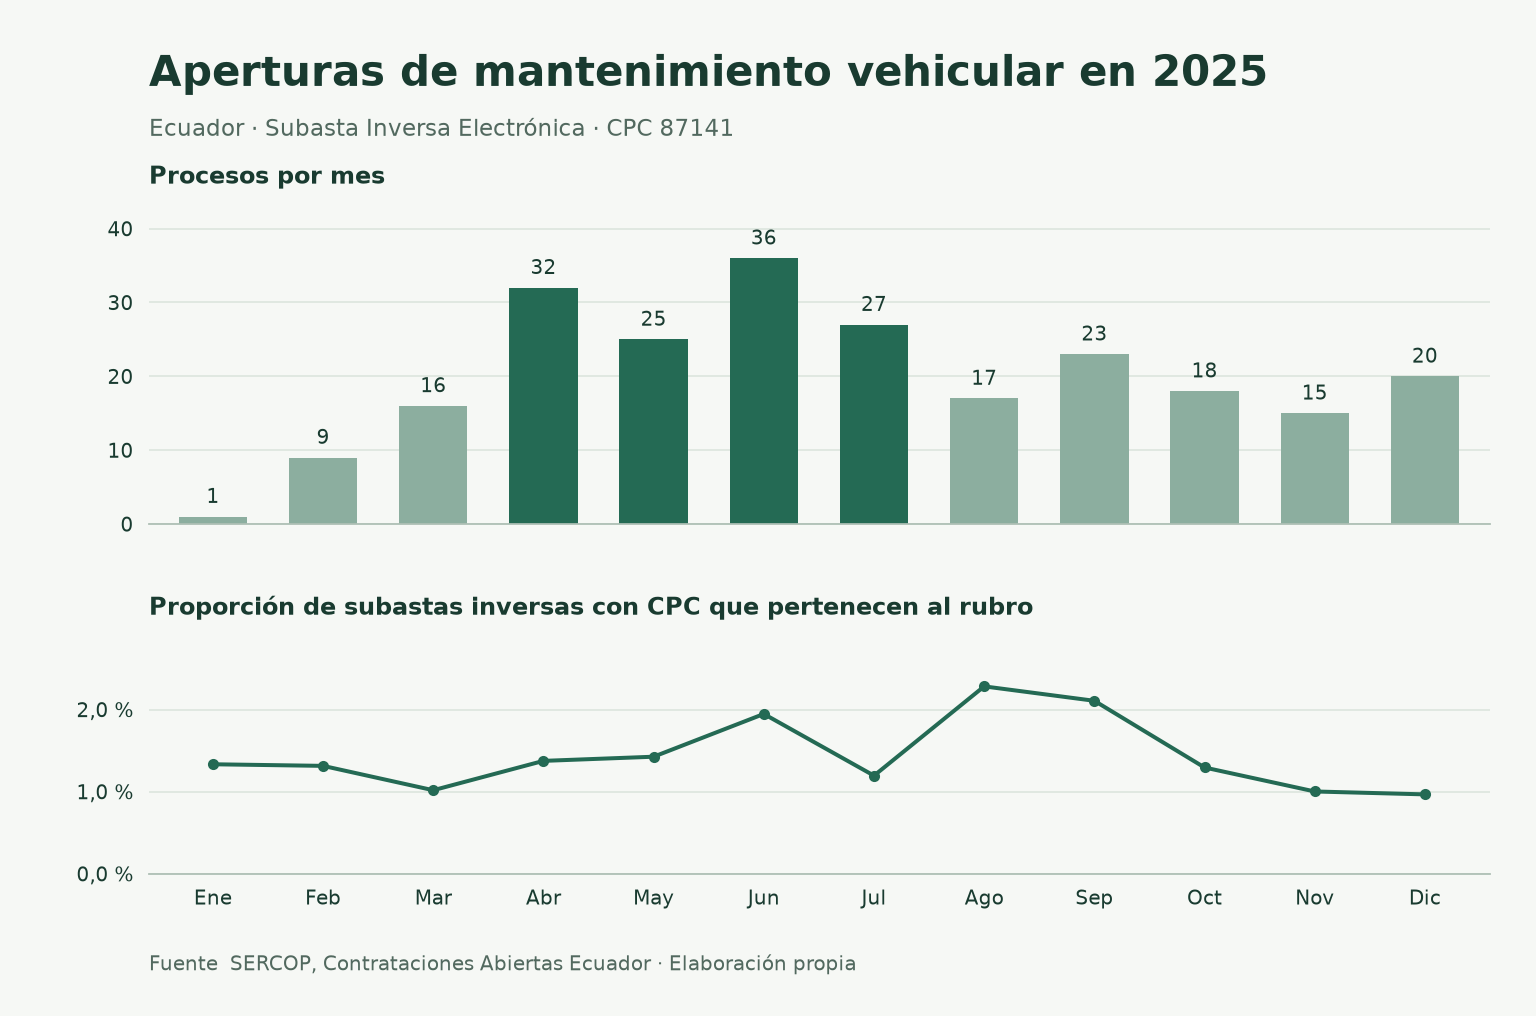

De abril a julio hubo **120 aperturas** (50,2 % del total del rubro).

In [3]:
meses = [c["mes"].month for c in cortes]
conteos = [c["procesos_piloto"] for c in cortes]
tasas = [100 * c["procesos_piloto"] / (c["procesos"] - c["sin_cpc"])
         if c["procesos"] > c["sin_cpc"] else float("nan") for c in cortes]
cuatro_meses = sum(c["procesos_piloto"] for c in cortes if 4 <= c["mes"].month <= 7)

fig, (arriba, abajo) = plt.subplots(
    2, 1, sharex=True, figsize=(9.6, 6.35), height_ratios=(1.35, 1),
)
fondo, tinta, verde = "#f6f8f5", "#193b30", "#246a54"
fig.patch.set_facecolor(fondo)
fig.subplots_adjust(left=.097, right=.97, top=.793, bottom=.14, hspace=.43)
fig.text(.097, .947, "Aperturas de mantenimiento vehicular en 2025",
         fontsize=19, weight="bold", color=tinta, va="top")
fig.text(.097, .884, "Ecuador · Subasta Inversa Electrónica · CPC 87141",
         fontsize=10.5, color="#52695f", va="top")

for eje in (arriba, abajo):
    eje.set_facecolor(fondo)
    eje.set_axisbelow(True)
    eje.grid(axis="y", color="#dce5de", linewidth=.75)
    eje.spines[["top", "right", "left"]].set_visible(False)
    eje.spines["bottom"].set_color("#aebfb5")
    eje.tick_params(colors=tinta, length=0, labelsize=9, pad=7)
    eje.set_xlim(.42, 12.59)

barras = arriba.bar(meses, conteos, width=.62, color=[
    verde if 4 <= mes <= 7 else "#8cae9f" for mes in meses
])
arriba.bar_label(barras, padding=4, fontsize=9, color=tinta)
arriba.set_title("Procesos por mes", loc="left", color=tinta, fontsize=11, pad=12, weight="bold")
arriba.set_ylim(0, max(conteos) * 1.18)

abajo.plot(meses, tasas, color=verde, marker="o", linewidth=1.8, markersize=4)
abajo.set_title("Proporción de subastas inversas con CPC que pertenecen al rubro",
                loc="left", color=tinta, fontsize=11, pad=12, weight="bold")
abajo.set_ylim(0, max(tasa for tasa in tasas if tasa == tasa) * 1.24)
abajo.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{numero(valor, 1)} %"))
abajo.set_xticks(meses, nombres_mes)
fig.text(.097, .045, "Fuente  SERCOP, Contrataciones Abiertas Ecuador · Elaboración propia",
         fontsize=9, color="#52695f")

imagen = BytesIO()
fig.savefig(imagen, format="png", dpi=160, facecolor=fondo)
plt.close(fig)
display(Image(data=imagen.getvalue(), width=940))
display(Markdown(f"De abril a julio hubo **{cuatro_meses} aperturas** "
                 f"({porcentaje(cuatro_meses, len(procesos))} del total del rubro)."))

## Oferentes y fechas disponibles

Se coteja el número publicado de oferentes con los IDs distintos de tender.tenderers en los ZIP de la misma carga. El análisis de competencia usa los procesos con al menos una adjudicación registrada. El conteo incluye a quienes presentaron una oferta según el estándar OCDS.

[Campo numberOfTenderers en OCDS](https://standard.open-contracting.org/latest/en/schema/reference/)

In [4]:
por_ocid = {p["ocid"]: p for p in procesos}
revisados = set()
detalle_oferentes = Counter()
fechas_cierre = 0
for corte in cortes:
    origen = {"mes": corte["mes"].strftime("%Y-%m"), "sha256": corte["sha256_zip"]}
    for fila in filas_del_corte(leer_zip(leer_crudo(origen))):
        ocid = fila["ocid"]
        if ocid not in por_ocid:
            continue
        licitacion = fila["tender"]
        oferentes = {o["id"] for o in (licitacion.get("tenderers") or []) if o.get("id")}
        comparables = oferentes and por_ocid[ocid]["numero_oferentes"] is not None
        if comparables:
            detalle_oferentes["Coincide" if len(oferentes) == por_ocid[ocid]["numero_oferentes"] else "Difiere"] += 1
        else:
            detalle_oferentes["Sin detalle comparable"] += 1
        fechas_cierre += bool((licitacion.get("tenderPeriod") or {}).get("endDate"))
        revisados.add(ocid)

assert revisados == set(por_ocid)
tabla(
    ("Control de la descarga original", "Procesos"),
    [
        ("Número de oferentes coincide con IDs únicos", detalle_oferentes["Coincide"]),
        ("Número de oferentes difiere de los IDs únicos", detalle_oferentes["Difiere"]),
        ("Sin detalle de oferentes comparable", detalle_oferentes["Sin detalle comparable"]),
        ("Con fecha de cierre en tenderPeriod.endDate", fechas_cierre),
    ],
)

adjudicados = [p for p in procesos if p["adjudicado"]]
con_oferentes = [p["numero_oferentes"] for p in adjudicados if p["numero_oferentes"] is not None]
uno_dos = sum(1 <= n <= 2 for n in con_oferentes)
tabla(
    ("Oferentes publicados", "Procesos adjudicados", "Proporción con conteo"),
    [(n, cantidad, porcentaje(cantidad, len(con_oferentes)))
     for n, cantidad in sorted(Counter(con_oferentes).items())],
)
display(Markdown(f"**{uno_dos} de {len(con_oferentes)}** adjudicados con conteo tuvieron 1 o 2 oferentes. "
                 f"Sin conteo de oferentes: {len(adjudicados) - len(con_oferentes)} adjudicados."))

| Control de la descarga original | Procesos |
| --- | --- |
| Número de oferentes coincide con IDs únicos | 239 |
| Número de oferentes difiere de los IDs únicos | 0 |
| Sin detalle de oferentes comparable | 0 |
| Con fecha de cierre en tenderPeriod.endDate | 0 |

| Oferentes publicados | Procesos adjudicados | Proporción con conteo |
| --- | --- | --- |
| 1 | 58 | 26,2 % |
| 2 | 81 | 36,7 % |
| 3 | 37 | 16,7 % |
| 4 | 20 | 9,0 % |
| 5 | 12 | 5,4 % |
| 6 | 4 | 1,8 % |
| 7 | 8 | 3,6 % |
| 8 | 1 | 0,5 % |

**139 de 221** adjudicados con conteo tuvieron 1 o 2 oferentes. Sin conteo de oferentes: 0 adjudicados.

## Tiempo hasta la primera firma

Se mide en días calendario a partir de la apertura. Cada proceso contribuye con su primera firma observada igual o posterior a la apertura. La cohorte para el plazo incluye únicamente procesos con una firma utilizable al corte.

In [5]:
primera_firma = {}
fechas_inconsistentes = 0
for contrato in contratos:
    firma = contrato["firma"]
    if firma and firma < contrato["apertura"]:
        fechas_inconsistentes += 1
    if firma and firma >= contrato["apertura"]:
        ocid = contrato["ocid"]
        primera_firma[ocid] = min(firma, primera_firma.get(ocid, firma))

dias = [(firma - por_ocid[ocid]["apertura"]).days for ocid, firma in primera_firma.items()]
p25_dias, p50_dias, p75_dias = quantiles(dias, n=4, method="inclusive")
mas_de_sesenta = sum(dia > 60 for dia in dias)
tabla(
    ("Control de firmas", "Resultado"),
    [
        ("Procesos con firma utilizable", len(dias)),
        ("Procesos sin firma utilizable al corte", len(procesos) - len(dias)),
        ("Contratos con firma anterior a apertura", fechas_inconsistentes),
        ("P25 / mediana / P75", f"{numero(p25_dias)} / {numero(p50_dias)} / {numero(p75_dias)} días"),
        ("Más de 60 días", f"{mas_de_sesenta} ({porcentaje(mas_de_sesenta, len(dias))})"),
        ("Primera firma posterior a 2025", sum(firma.year > 2025 for firma in primera_firma.values())),
    ],
)

| Control de firmas | Resultado |
| --- | --- |
| Procesos con firma utilizable | 201 |
| Procesos sin firma utilizable al corte | 38 |
| Contratos con firma anterior a apertura | 0 |
| P25 / mediana / P75 | 33 / 42 / 56 días |
| Más de 60 días | 35 (17,4 %) |
| Primera firma posterior a 2025 | 20 |

## Tamaño de contrato y valores extremos

Se usan valores de contratos en USD mayores que cero para describir tamaños. Se calcula el intervalo central P25–P75 y se señalan casos por encima de P75 + 1,5 × (P75 − P25) para leer su alcance. Las comparaciones por código usan contratos vinculados a procesos con un solo CPC y al menos 15 contratos en el grupo. Un código puede reunir servicios con cantidades y condiciones diferentes.

[Política de publicación de SERCOP](https://datosabiertos.compraspublicas.gob.ec/PLATAFORMA/documentos/politica-publicacion-SERCOP-OCDS.pdf)

In [6]:
validos = [c for c in contratos if c["moneda"] == "USD" and c["monto"] is not None and c["monto"] > 0]
montos = [c["monto"] for c in validos]
p25, p50, p75 = quantiles(montos, n=4, method="inclusive")
p90 = quantiles(montos, n=10, method="inclusive")[8]
umbral = p75 + Decimal("1.5") * (p75 - p25)
extremos = sorted((c for c in validos if c["monto"] > umbral), key=lambda c: c["monto"], reverse=True)
tabla(
    ("Control de montos", "Resultado"),
    [
        ("Contratos con monto positivo en USD", len(validos)),
        ("Contratos fuera del filtro de monto y moneda", len(contratos) - len(validos)),
        ("P25 / mediana / P75", " / ".join(f"USD {numero(v, 2)}" for v in (p25, p50, p75))),
        ("P90", f"USD {numero(p90, 2)}"),
        ("Umbral de revisión", f"USD {numero(umbral, 2)}"),
        ("Casos sobre el umbral", len(extremos)),
        ("Contratos del piloto sin proveedor enlazado", sum(not c["tiene_proveedor"] for c in contratos)),
    ],
)

por_cpc = defaultdict(list)
for contrato in validos:
    if len(contrato["cpcs"]) == 1:
        por_cpc[contrato["cpcs"][0]].append(contrato["monto"])

tabla(
    ("Código único del proceso", "Contratos", "P25 en USD", "Mediana en USD", "P75 en USD"),
    [(cpc, len(valores), *(numero(v, 2) for v in quantiles(valores, n=4, method="inclusive")))
     for cpc, valores in sorted(por_cpc.items(), key=lambda par: (-len(par[1]), par[0]))
     if len(valores) >= 15],
)
tabla(
    ("OCID a revisar", "Monto en USD", "Objeto declarado"),
    [(c["ocid"], numero(c["monto"], 2), c["objeto"]) for c in extremos[:3]],
)

| Control de montos | Resultado |
| --- | --- |
| Contratos con monto positivo en USD | 201 |
| Contratos fuera del filtro de monto y moneda | 0 |
| P25 / mediana / P75 | USD 15.699,00 / USD 28.446,39 / USD 54.200,00 |
| P90 | USD 118.000,00 |
| Umbral de revisión | USD 111.951,50 |
| Casos sobre el umbral | 24 |
| Contratos del piloto sin proveedor enlazado | 1 |

| Código único del proceso | Contratos | P25 en USD | Mediana en USD | P75 en USD |
| --- | --- | --- | --- | --- |
| 871410011 | 99 | 18.503,22 | 30.182,88 | 53.700,00 |
| 871410018 | 30 | 13.484,75 | 30.000,00 | 58.137,25 |
| 871410012 | 17 | 13.185,00 | 21.680,76 | 42.739,57 |
| 871410017 | 15 | 13.332,56 | 20.367,00 | 53.651,20 |

| OCID a revisar | Monto en USD | Objeto declarado |
| --- | --- | --- |
| ocds-5wno2w-SIE-GADMLT-2025-025-2670 | 381.381,93 | SERVICIO DE MANTENIMIENTO CORRECTIVO INCLUYE REPUESTOS Y ACCESORIOS MULTIMARCA DE LOS VEHICULOS MAQUINARIAS Y EQUIPOS DEL GAD MUNICIPAL LA TRONCAL |
| ocds-5wno2w-SIE-GADP-S-2025-023-3277 | 283.494,33 | SERVICIO DE MANTENIMIENTO CORRECTIVO PARA LA MAQUINARIA PESADA PERTENECIENTE AL GADPS, PERÍODO 2025 |
| ocds-5wno2w-SIE-GADP-S-2025-013-3277 | 282.200,00 | SERVICIO DE MANTENIMIENTO CORRECTIVO PARA LOS VEHICULOS PESADOS PERTENECIENTES AL GADPS, PERÍODO 2025 |

## Uso del análisis

El [informe de hallazgos](../docs/fase-3-hallazgos.md) traduce estas métricas a decisiones para un proveedor. Su utilidad práctica y la disposición a pagar quedan por validar en entrevistas. Las cifras describen el alcance y la captura indicados al inicio.